In [2]:
from langgraph.graph import StateGraph , START, END
from typing import TypedDict


In [10]:
class Fine(TypedDict):
    et : int
    st : int

    fine : int
    period : int


In [15]:
def calfine(state:Fine)->Fine:
    fine = (state['et'] - state['st'])*100

    return {'fine':fine}

In [16]:
def calperiod(state : Fine) -> Fine:
    period = state['et'] - state['st']

    return {'period':period}

In [17]:
graph = StateGraph(Fine)

graph.add_node('calfine',calfine)
graph.add_node('calperiod',calperiod)


graph.add_edge(START,'calfine')
graph.add_edge(START,'calperiod')

graph.add_edge('calfine',END)
graph.add_edge('calperiod',END)


wf = graph.compile()



In [18]:
wf.invoke({'st':7,'et':12})

{'et': 12, 'st': 7, 'fine': 500, 'period': 5}

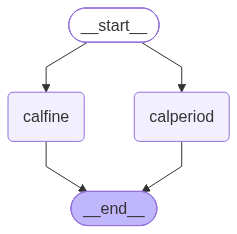

In [19]:
wf